# [실습] 회귀 — 숫자를 예측하고 오차로 말하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 2 실습. 이 집은 얼마에 팔릴까?

**필수 머신러닝 · Chapter 2**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 베이스라인 고르기 |
| Part 3 | 현행 방법 만들기: 사람의 시세 규칙 |
| Part 4 | 모델 만들기와 실험 기록 |
| Part 5 | 오차 들여다보기와 보고 |

## 분석 의뢰서

> **의뢰 부서**: 부동산 플랫폼 기획팀
> **목적**: 매물을 등록할 때 "이 집은 대략 얼마" 하는 적정 시세를 자동으로 제시하고 싶다.
> **제약**: 시세가 실제 거래가와 너무 다르면 판매자와 구매자 모두 플랫폼을 믿지 않게 된다.
> **질문**: 집의 정보로 거래가를 얼마나 정확히 예측할 수 있을까?

## 이 실습의 질문

> **기획팀에 "이 모델의 시세는 평균적으로 ±얼마"라고 말한다면, 어떤 지표로 얼마라고 말할 것인가? 그리고 그 숫자를 믿어도 되는 집과 믿으면 안 되는 집은 어떻게 다른가?**

Chapter 1과 같은 순서로 진행합니다. 여러분이 먼저 중개사처럼 **사람의 시세 규칙**을 만들고, 그 시세 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 기획팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

Kaggle의 House Prices 대회 데이터인 `train.csv`(Ames Housing, 1,460채)를 이 노트북과 같은 폴더에 두세요.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

강의에서는 피처 다섯 개만 썼습니다. 여기서는 데이터에 실제로 어떤 문제가 들어 있는지 직접 확인하고, 그 문제를 어떻게 다룰지 스스로 정합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** `train.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 쓰세요. 열이 많아서 `df.head()`는 일부만 보입니다.
</details>

In [10]:
# 여기에 코드를 작성하세요
df = pd.read_csv("train.csv")

print(df.shape)
print(df.head())
print(df.columns.tolist())

(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008  

## 1-2. 거래가 살펴보기

**[직접 작성]** 거래가(`SalePrice`)의 평균, 중앙값, 최솟값, 최댓값을 확인하세요.

<details><summary>힌트</summary>

`df["SalePrice"].describe()`가 한 번에 보여 줍니다. 중앙값은 `50%` 줄입니다.
</details>

In [11]:
# 여기에 코드를 작성하세요

df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

**[제공]** 거래가의 분포를 그려 봅니다.

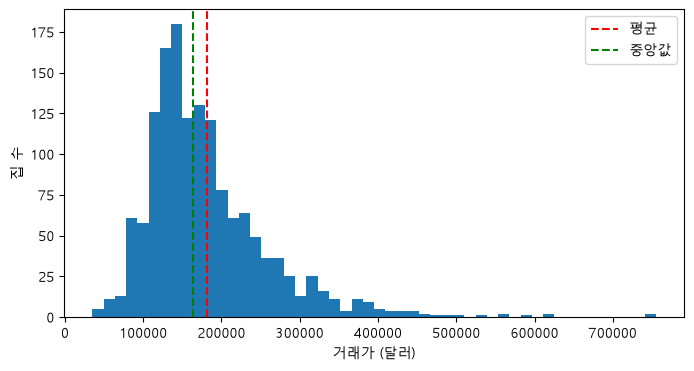

In [12]:
# [제공] 거래가 분포
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["SalePrice"], bins=50)
ax.axvline(df["SalePrice"].mean(), color="red", linestyle="--", label="평균")
ax.axvline(df["SalePrice"].median(), color="green", linestyle="--", label="중앙값")
ax.set_xlabel("거래가 (달러)")
ax.set_ylabel("집 수")
ax.legend()
plt.show()

> **[판단]** 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 이유는 무엇이고, 이 특징이 "모델이 크게 틀리는 집"에 어떤 영향을 줄 것 같나요?
>
> 나의 답: 평균값이 더 크다. 대부분의 집이 10~25만 달러에 몰려있지만 40만 달러가 넘는 비싼 집이 소수 있어 평균을 위로 끌어올리기 때문이다. 이런 비싼 집들은 학습 데이터에 적어서 모델이 잘 배우지 못하게 되고 실제보다 낮게 예측하기 쉽다. 또한 가격이 크기 때문에 오차 금액도 클 것이다. 따라서 크게 틀리는 집은 주로 비싼 집일 것이다.

## 1-3. 빈 값 찾기

**[직접 작성]** 빈 값이 있는 열을 빈 값이 많은 순서로 10개 확인하세요.

<details><summary>힌트</summary>

`df.isna().sum()`은 열마다 빈 값의 수를 셉니다. `.sort_values(ascending=False)`로 정렬하고 `.head(10)`으로 위쪽만 보세요.
</details>

In [18]:
# 여기에 코드를 작성하세요
df.isna().sum().sort_values(ascending=False).head(10)

df["PoolQC"].value_counts()

PoolQC
Gd    3
Ex    2
Fa    2
Name: count, dtype: int64

> **[판단]** 수영장 품질(`PoolQC`)이 1,453채나 비어 있습니다. 정말로 정보가 없는 걸까요, 아니면 다른 뜻일까요? 데이터 설명서에서는 이런 열의 빈 값(NA)을 "해당 시설 없음"으로 정의합니다. 이 점을 알면 빈 값을 어떻게 다루겠습니까?
>
> 나의 답: 정보가 없는 것이 아니라 수영장이 없다는 뜻이다. 그래서 행을 지우거나 평균으로 채우면 안된다. 수영장 품질의 값을 보면 Gd, Ex, Fa 이렇게 세 가지 글자 범주로 되어 있어 0같은 숫자를 넣으면 형식이 섞인다. 따라서 None으로 채워 수영장 없음이라는 하나의 범주로 다루겠다. 

## 1-4. 이 실습에서 쓰는 피처 정하기

79개를 전부 쓰면 첫 실습으로는 너무 많아서, 이 실습에서 쓸 피처 몇 개를 미리 골라 두었습니다. **[제공]** 셀을 실행해 목록을 확인하세요.

In [19]:
# [제공] 이 실습에서 쓰는 피처 목록
num_features = ["GrLivArea", "OverallQual", "YearBuilt", "YearRemodAdd", "TotalBsmtSF", "GarageCars",
                "GarageArea", "LotArea", "FullBath", "TotRmsAbvGrd", "Fireplaces", "1stFlrSF"]
cat_features = ["Neighborhood", "ExterQual", "KitchenQual", "BsmtQual", "CentralAir", "MSSubClass"]

print("숫자형:", num_features)
print("범주형:", cat_features)
print()
print("선택한 피처 중 빈 값이 있는 열:")
print(df[num_features + cat_features].isna().sum()[lambda s: s > 0])
print()
print("MSSubClass의 값:", sorted(df["MSSubClass"].unique().tolist()))

숫자형: ['GrLivArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'TotalBsmtSF', 'GarageCars', 'GarageArea', 'LotArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', '1stFlrSF']
범주형: ['Neighborhood', 'ExterQual', 'KitchenQual', 'BsmtQual', 'CentralAir', 'MSSubClass']

선택한 피처 중 빈 값이 있는 열:
BsmtQual    37
dtype: int64

MSSubClass의 값: [20, 30, 40, 45, 50, 60, 70, 75, 80, 85, 90, 120, 160, 180, 190]


> **[판단]** `MSSubClass`(주택 유형)는 20, 30, 60, 120… 처럼 숫자로 저장되어 있습니다. 이 숫자들은 "크기"를 뜻할까요? 이 열을 숫자 그대로 회귀에 넣으면 어떤 문제가 생길까요?
>
> 나의 답: 크기를 뜻하지 않는다. 숫자는 주택 유형을 구분하는 코드 번호일 뿐이므로 범주로 다뤄야 한다. 숫자 그대로 회귀에 넣으면 모델은 120이 20보다 6배 크다 등 번호가 커질 수록 집값이 오르거나 떨어진다고 가정할 것이다. 하지만 실제로는 유형 사이에는 그런 순서나 간격이 없으므로 유형별 차이를 제대로 배우지 못한다.

**[직접 작성]** 아래 두 가지를 처리하세요.

1. `MSSubClass`를 글자(범주)로 바꾼다
2. 범주형 피처(`cat_features`)의 빈 값을 `"None"`이라는 값으로 채운다

그다음 선택한 피처에 빈 값이 남지 않았는지 확인합니다.

<details><summary>힌트</summary>

`df["MSSubClass"] = df["MSSubClass"].astype(str)`, `df[cat_features] = df[cat_features].fillna("None")`. 확인은 `df[num_features + cat_features].isna().sum().sum()`이 0인지 보면 됩니다.
</details>

In [21]:
# 여기에 코드를 작성하세요
df["MSSubClass"] = df["MSSubClass"].astype(str)

df[cat_features] = df[cat_features].fillna("None")

print(df[num_features + cat_features].isna().sum().sum())

0


> **[판단]** 범주형의 빈 값을 "None"이라는 값으로 채운 것은 1-3에서 본 "해당 시설 없음"이라는 설명서의 정의에 근거한 결정입니다. 이 결정이 틀릴 수 있는 경우를 하나 생각해 보세요. (예: 정말로 기록이 누락된 경우)
>
> 나의 답: 정말 수영장이 있는데 데이터 오류로 누락되는 경우가 있을 수도 있다. 이런 경우 수영장이 있고 수영장 품질도 좋은데 None로 처리되어 회귀에 잘못된 정보를 학습시키게 될 수 있다. 이런 경우는 다른 열로 교차 확인할 수 있다.

## 1-5. 평가용 데이터 먼저 떼어 두기

Chapter 1과 같은 원칙입니다. 이후의 탐색과 시세 규칙은 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`로 합니다. (회귀 문제이므로 `stratify`는 쓰지 않습니다.)

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)`
</details>

In [22]:
# 여기에 코드를 작성하세요
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-4의 처리와 1-5의 분할을 한 번에 합니다. 끝낸 사람은 실행하지 않아도 됩니다.

In [23]:
# [제공] 체크포인트: 1-5까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("train.csv")
df["MSSubClass"] = df["MSSubClass"].astype(str)
df[cat_features] = df[cat_features].fillna("None")
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
print(len(train_df), len(test_df))

1168 292


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `evaluate(이름, 예측)` | 평가용 데이터에서 MAE·RMSE·R²·MAPE를 보여 주고 지표를 돌려준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 (범주형은 원핫 인코딩) |
| `log_result(...)` | 실험 결과를 기록표에 한 줄 추가한다 |
| `run(이름, 피처, 모델)` | 모델을 학습하고 학습용·평가용 점수를 모두 채점해 기록한다 |
| `error_by_price(예측)` | 가격대별 집 수·MAE·평균 편향을 보여 준다 |

In [24]:
# [제공] 실습 도구
y_test = test_df["SalePrice"]
preds = {}          # 실험 이름 → 평가용 데이터의 예측값
experiment_log = []

def metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R²": r2_score(y, pred),
            "MAPE": mean_absolute_percentage_error(y, pred)}

def evaluate(name, pred, y_true=None):
    """예측을 채점합니다. y_true를 주지 않으면 평가용 데이터로 채점합니다."""
    store = y_true is None
    y_true = y_test if store else y_true
    pred = np.asarray(pred)
    m = metrics(y_true, pred)
    print(f"[{name}] MAE {m['MAE']:,.0f} | RMSE {m['RMSE']:,.0f} | R² {m['R²']:.3f} | MAPE {m['MAPE']*100:.1f}%")
    if store:
        preds[name] = pd.Series(pred, index=test_df.index)
    return m

def log_result(name, features, test, train=None):
    experiment_log.append({
        "실험": name,
        "피처 수": len(features) if features else "-",
        "학습 MAE": round(train["MAE"]) if train else None,
        "학습 RMSE": round(train["RMSE"]) if train else None,
        "평가 MAE": round(test["MAE"]),
        "평가 RMSE": round(test["RMSE"]),
        "평가 R²": round(test["R²"], 3),
    })

def make_data(features):
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["SalePrice"], test_df["SalePrice"]

def run(name, features, model):
    """모델을 학습하고 학습용·평가용 점수를 채점해 기록표에 남깁니다."""
    X_tr, X_te, y_tr, y_te = make_data(features)
    model.fit(X_tr, y_tr)
    m_tr = evaluate(name + " (학습용)", model.predict(X_tr), y_true=y_tr)
    m_te = evaluate(name, model.predict(X_te))
    log_result(name, features, m_te, m_tr)
    return model

_bins = [0, 100000, 200000, 300000, 500000, 800000]
def error_by_price(pred):
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    res = y_test - pred
    g = pd.cut(y_test, _bins)
    return pd.DataFrame({"집 수": g.value_counts().sort_index(),
                         "MAE": res.abs().groupby(g, observed=True).mean().round(0),
                         "평균 편향(실제−예측)": res.groupby(g, observed=True).mean().round(0)})

## 1-6. 집값과 관련 있어 보이는 정보 찾기

**[직접 작성]** 학습용 데이터(`train_df`)에서 두 가지를 확인하세요.

1. 숫자 열 중 거래가와 상관이 높은 열 10개
2. 동네(`Neighborhood`)별 거래가 중앙값 (높은 순)

<details><summary>힌트</summary>

상관은 `train_df.corr(numeric_only=True)["SalePrice"]`, 동네별 중앙값은 `train_df.groupby("Neighborhood")["SalePrice"].median()`입니다. 둘 다 `.sort_values(ascending=False)`로 정렬하세요.
</details>

In [28]:
# 여기에 코드를 작성하세요
corr = train_df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False).head(11)
print(corr)
nbhd = train_df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
print(nbhd)

SalePrice       1.000000
OverallQual     0.785555
GrLivArea       0.695652
GarageCars      0.640991
GarageArea      0.624139
TotalBsmtSF     0.597766
1stFlrSF        0.587883
FullBath        0.552546
TotRmsAbvGrd    0.520388
YearBuilt       0.516501
YearRemodAdd    0.508593
Name: SalePrice, dtype: float64
Neighborhood
NridgHt    314813.0
NoRidge    290000.0
StoneBr    282000.0
Veenker    245500.0
Somerst    226700.0
Timber     226250.0
ClearCr    211000.0
Crawfor    208550.0
CollgCr    200500.0
Gilbert    184000.0
NWAmes     183950.0
Blmngtn    181000.0
SawyerW    179200.0
Mitchel    156950.0
NPkVill    147000.0
NAmes      142000.0
SWISU      139500.0
Sawyer     134950.0
OldTown    124000.0
Blueste    124000.0
Edwards    123500.0
BrkSide    120000.0
IDOTRR     108950.0
BrDale     100000.0
MeadowV     89500.0
Name: SalePrice, dtype: float64


**[제공]** 거주 면적과 거래가의 관계를 그려 봅니다.

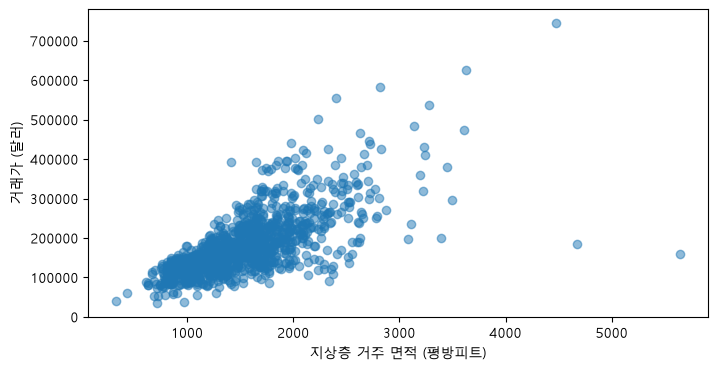

In [29]:
# [제공] 거주 면적과 거래가 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train_df["GrLivArea"], train_df["SalePrice"], alpha=0.5)
ax.set_xlabel("지상층 거주 면적 (평방피트)")
ax.set_ylabel("거래가 (달러)")
plt.show()

> **[판단]** 거래가와 가장 관련이 깊어 보이는 숫자 열 세 개를 적고, 왜 그럴지 한 줄씩 설명하세요.
>
> 나의 답: OverallQual: 0.785555, GrLivArea: 0.695652, GarageCars: 0.640991로 상관계수가 가장 높다.     >   OverallQual: 자재와 마감 품질이 좋을수록 짓는 비용이 많이 들고 사는 사람도 높게 평가하므로 거래가가 높다.
>   GrLivArea: 지상 생활 면적이 넓을수록 쓸 수 있는 공간이 많아 거래가가 높다.
>   GarageCars: 차를 여러 대 넣을 수 있는 차고가 있는 집은 대체로 크고 고급스러운 집이라 거래가도 함께 높다.

> **[판단]** 산점도에서 눈에 띄는 점이 있나요? (예: 면적에 비해 값이 이상한 집) 이런 집을 모델에서 빼도 될까요, 두어야 할까요?
>
> 나의 답: 지상 생활 면적이 약 4,700과 5,600평방피트로 가장 넓은데 거래가가 20만 달러도 안 되는 집이 두 채 있다. 면적이 아닌 다른 이유로 가격이 낮았을 가능성이 크므로 다른 열을 먼저 확인해야한다. 그 원인을 피처로 넣지 않는다면 모델은 이 집들이 왜 싼지 설명하지 못하고 면적과 가격의 관계를 잘못 배우게 된다. 따라서 원인이 특수한 거래로 확인되면 학습용 데이터에서 빼겠다.

---
# Part 2. 베이스라인 고르기

강의 2-1에서 회귀의 베이스라인은 "모든 집은 평균 가격"이라고 배웠습니다. 그런데 "평균 가격"만이 유일한 선택일까요?

## 2-1. 평균 예측과 중앙값 예측

**[직접 작성]** 학습용 데이터의 거래가 **평균**과 **중앙값**을 각각 평가용 집 전체의 예측값으로 쓴 두 베이스라인을 `evaluate`로 채점하고, 결과 지표를 `m_mean`, `m_median`에 저장하세요. 이어서 두 결과를 `log_result`로 기록합니다.

<details><summary>힌트</summary>

`mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())`로 같은 값을 반복한 배열을 만듭니다. 중앙값도 같은 방식입니다.

`m_mean = evaluate("평균 예측", mean_pred)`, 그다음 `log_result("평균 예측", [], m_mean)`.
</details>

In [32]:
# 여기에 코드를 작성하세요
train_mean = train_df["SalePrice"].mean()
train_median = train_df["SalePrice"].median()

mean_pred = np.full(len(test_df), train_mean)
median_pred = np.full(len(test_df), train_median)

m_mean = evaluate("평균 예측", mean_pred)
m_median = evaluate("중앙값 예측", median_pred)

log_result("평균 예측", [], m_mean)
log_result("중앙값 예측", [], m_median)

[평균 예측] MAE 62,576 | RMSE 87,619 | R² -0.001 | MAPE 41.4%
[중앙값 예측] MAE 59,568 | RMSE 88,667 | R² -0.025 | MAPE 36.0%


> **[판단]** MAE와 RMSE에서 평균 예측과 중앙값 예측 중 어느 쪽이 더 낮은가요? 두 지표에서 결과가 다르다면, 왜 그럴지 "큰 오차를 얼마나 아프게 보는가"로 설명해 보세요.
>
> 나의 답: MAE 경우 중앙값 예측이 더 낮고 RMSE 평균 예측이 더 낮다. MAE는 오차를 크기 그대로 평균 내지만, RMSE는 오차를 제곱하므로 큰 오차를 훨씬 아프게 본다. 중앙값은 평균보다 낮아서 대부분을 차지하는 보통 가격의 집은 더 가깝게 맞히지만 소수의 비싼 집은 더 크게 틀린다는 의미이다.

> **[판단]** 회귀 모델의 점수를 비교할 베이스라인으로는 둘 중 어느 것을 쓰겠습니까? 이유도 적으세요.
>
> 나의 답: 중앙값을 베이스라인으로 쓰겠다. MAE와 MAPE 모두 중앙값 예측이 더 낮다. 대부분을 차지하는 보통 가격의 집을 더 가깝게 맞힌다는 의미이다. RMSE는 위에 적혀있듯이 소수의 집들에 의해서이다.

---
# Part 3. 현행 방법 만들기: 사람의 시세 규칙

모델이 없던 시절에도 중개사들은 나름의 규칙으로 시세를 매겼습니다. 비슷한 집의 평방피트당 단가에 면적을 곱하거나, 같은 동네의 비슷한 집이 얼마에 팔렸는지 떠올리는 식입니다. 여러분이 중개사라면 **정보 두세 개**로 어떤 규칙을 만들겠습니까?

**시세 규칙**: 어떤 정보를 어떻게 쓸지 **내가 정하고**, 숫자(동네별 단가 등)는 학습용 데이터에서 계산하는 방법입니다. Chapter 1에서 배운 규칙 기반(Rule-Based) 방법의 한 예로, 모델이 이겨야 할 비교 기준이 됩니다.

## 시세 규칙을 만들 때의 약속

- 쓰는 정보는 **두세 개를 넘기지 않습니다.** 머릿속으로 계산할 수 있어야 하기 때문입니다.
- 시세 규칙에 쓰는 숫자(동네별 단가, 구간별 중앙값 등)는 **학습용 데이터에서만** 계산합니다.
- 평가용 데이터를 보고 시세 규칙을 고치지 않습니다.

## 3-1. 나의 시세 규칙 만들기

> **[판단]** 나의 시세 규칙(말로): 집의 ______ 와 ______ 를 보고, ______ 를 기준으로 가격을 정한다.
>
> 이 정보를 고른 근거(1-6의 어떤 결과인가): 
>
> 나의 답:나의 시세 규칙(말로): 집의 전반적인 품질(overallqual) 와 지상생활면적(Grlivarea) 를 보고, 같은 품질 등급 집들의 평방피트당 단가(중앙값)를 기준으로 가격을 정한다.
> 이 정보를 고른 근거(1-6의 어떤 결과인가): 1-6에서 거래가와 상관계수가 가장 높은 두 열이 OverallQual(0.786)과 GrLivArea(0.696)였다. 품질은 단가를, 면적은 크기를 정하므로 둘을 곱하여 값을 구할 수 있다.

**[직접 작성]** 시세 규칙을 코드로 옮겨 평가용 집의 가격을 계산하고, 예측을 `rule_pred`(평가용 `test_df`와 같은 순서의 `Series`)에 저장하세요. 그다음 `evaluate`로 채점하고, 결과를 `m_rule`에 저장한 뒤 `log_result`로 기록합니다.

<details><summary>힌트</summary>

학습용 데이터에서 평방피트당 단가를 구하는 예시입니다.

```python
unit_price = (train_df["SalePrice"] / train_df["GrLivArea"]).median()
rule_pred = test_df["GrLivArea"] * unit_price
```

동네별로 단가를 다르게 쓰려면 단가를 동네별로 구한 뒤 `map`으로 붙입니다.

```python
unit_by_nb = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["Neighborhood"]).median()
rule_pred = test_df["Neighborhood"].map(unit_by_nb) * test_df["GrLivArea"]
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 시세 규칙을 쓰세요. 평가용에만 있는 동네가 있을 수 있으니, 빈 값이 생기면 `fillna(train_df["SalePrice"].median())`처럼 채우세요.
</details>

In [33]:
# 여기에 코드를 작성하세요
# 예측은 rule_pred, 채점 결과는 m_rule라는 이름으로 저장하세요 (Part 4, 5에서 다시 씁니다)

# 1. 학습용 데이터에서 품질 등급별 평방피트당 단가(중앙값) 계산
unit_by_qual = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["OverallQual"]).median()

# 2. 평가용 집에 적용: 그 집 등급의 단가 × 면적
rule_pred = test_df["OverallQual"].map(unit_by_qual) * test_df["GrLivArea"]

# 3. 학습용에 없던 등급이 있어 빈 값이 생기면, 전체 단가 × 면적으로 채우기
unit_all = (train_df["SalePrice"] / train_df["GrLivArea"]).median()
rule_pred = rule_pred.fillna(test_df["GrLivArea"] * unit_all)

# 4. 채점과 기록
m_rule = evaluate("시세 규칙(품질별 단가 × 면적)", rule_pred)
log_result("시세 규칙(품질별 단가 × 면적)", ["OverallQual", "GrLivArea"], m_rule)

[시세 규칙(품질별 단가 × 면적)] MAE 32,665 | RMSE 44,289 | R² 0.744 | MAPE 21.0%


> **[판단]** 내 시세 규칙의 MAE는 베이스라인(평균·중앙값 예측)보다 얼마나 낮은가요? 정보 두세 개만으로 오차가 이만큼 줄어든다는 것은 무엇을 뜻할까요?
>
> 나의 답: 내 시세 규칙의 MAE는 32,665로, 평균 예측(62,576)보다 29,911, 중앙값 예측(59,568)보다 26,903 낮아 오차가 거의 절반으로 줄었다. 품질과 면적이라는 정보 두 개만으로 이만큼 줄어든다는 것은, 집값의 상당 부분이 이 몇 가지 핵심 정보로 결정된다는 뜻이다.

---
# Part 4. 모델 만들기와 실험 기록

이제 모델을 만들어 내 시세 규칙과 겨룹니다. 강의 Part 2의 코드를 보지 말고 먼저 직접 써 보세요.

## 4-1. 첫 모델: 다중회귀

**[직접 작성]** 아래 순서로 작성하세요.

1. 피처 `["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]`로 `make_data`를 호출해 `X_train, X_test, y_train, y_test`를 만든다
2. `LinearRegression`을 학습한다
3. 학습용과 평가용을 모두 `evaluate`로 채점한다 (학습용은 `y_true=y_train`을 줍니다)
4. 평가용 결과를 `log_result`로 기록한다

<details><summary>힌트</summary>

강의 2-3의 코드와 같은 순서입니다.

```python
m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))
log_result("다중회귀 5개", features, m_test, m_train)
```
</details>

In [34]:
# 여기에 코드를 작성하세요
features = ["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]

X_train, X_test, y_train, y_test = make_data(features)

model = LinearRegression()
model.fit(X_train, y_train)

m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))
log_result("다중회귀 5개", features, m_test, m_train)


[학습용] MAE 24,399 | RMSE 37,970 | R² 0.758 | MAPE 14.5%
[다중회귀 5개] MAE 25,415 | RMSE 39,763 | R² 0.794 | MAPE 15.3%


> **[판단]** 이 모델의 학습용 점수와 평가용 점수는 얼마나 차이 나나요? 그 차이는 과적합의 신호일까요?
>
> 나의 답: 거의 차이가 나지 않는다. 평가용의 MAE는 학습용보다 1,016(약 4%), RMSE는 1,793(약 5%) 크고, MAPE는 0.8%p 높다. R²는 오히려 평가용이 더 높다(0.794 vs 0.758). 처음 보는 집에서 오차가 이 정도로만 늘어난 것은 자연스러운 수준이므로 과적합의 신호가 아니다. 모델이 학습 데이터에만 맞춘 것이 아니라 새로운 집에도 비슷하게 작동한다고 볼 수 있다.

## 4-2. 피처와 모델을 바꿔 보기

피처를 늘리거나 모델의 복잡도를 바꿔 가며 **세 번 이상** 실험하세요. 매번 아래 `run`이 학습용·평가용 점수를 모두 채점해 기록해 줍니다.

**[직접 작성]** `run(이름, 피처 목록, 모델)`을 세 번 이상 호출하세요. 다음 세 가지를 모두 포함하면 좋습니다.

- 숫자 피처만 늘려 보기
- 범주형 피처(동네, 마감 품질 등)를 더해 보기
- 모델의 복잡도를 올려 보기 (다항 피처)와, 그에 벌점을 주는 Ridge

<details><summary>힌트</summary>

```python
run("숫자 12개", num_features, LinearRegression())
run("숫자+범주", num_features + cat_features, LinearRegression())
run("3차 다항", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))
run("3차 다항 + Ridge", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=100)))
```

`alpha`(벌점의 세기)를 10, 100, 1000으로 바꿔 보면 학습용·평가용 점수가 어떻게 달라지는지 볼 수 있습니다.
</details>

In [35]:
# 실험 1
run("숫자 12개", num_features, LinearRegression())

# 실험 2
run("숫자+범주", num_features + cat_features, LinearRegression())

# 실험 3
run("3차 다항", num_features,
    make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))

# 실험 4~6


[숫자 12개 (학습용)] MAE 22,972 | RMSE 36,605 | R² 0.775 | MAPE 13.7%
[숫자 12개] MAE 24,353 | RMSE 39,231 | R² 0.799 | MAPE 14.5%
[숫자+범주 (학습용)] MAE 18,428 | RMSE 29,716 | R² 0.852 | MAPE 10.6%
[숫자+범주] MAE 20,172 | RMSE 32,698 | R² 0.861 | MAPE 11.9%
[3차 다항 (학습용)] MAE 11,736 | RMSE 16,646 | R² 0.954 | MAPE 7.2%
[3차 다항] MAE 29,235 | RMSE 67,319 | R² 0.409 | MAPE 17.8%


UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2879: illegal multibyte sequence

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2879: illegal multibyte sequence

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('polynomialfeatures', PolynomialFeatures(degree=3)),
                ('linearregression', LinearRegression())])

In [37]:
# 실험 4~6: 3차 다항에 Ridge 벌점 주기 (alpha 바꿔 가며)
for a in [10, 100, 1000]:
    run(f"3차 다항 + Ridge(α={a})", num_features,
        make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=a)))

[3차 다항 + Ridge(α=10) (학습용)] MAE 12,571 | RMSE 18,059 | R² 0.945 | MAPE 7.7%
[3차 다항 + Ridge(α=10)] MAE 22,671 | RMSE 41,122 | R² 0.780 | MAPE 13.5%
[3차 다항 + Ridge(α=100) (학습용)] MAE 13,872 | RMSE 19,911 | R² 0.934 | MAPE 8.5%
[3차 다항 + Ridge(α=100)] MAE 20,222 | RMSE 32,073 | R² 0.866 | MAPE 12.3%
[3차 다항 + Ridge(α=1000) (학습용)] MAE 17,013 | RMSE 23,963 | R² 0.904 | MAPE 10.5%
[3차 다항 + Ridge(α=1000)] MAE 20,858 | RMSE 31,688 | R² 0.869 | MAPE 13.2%


c:\Users\user\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.9651686077061597e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\user\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.9602249059270406e-06.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


**[제공]** 실험 기록표를 평가 MAE 순으로 봅니다.

In [38]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("평가 MAE")

,실험,피처 수,학습 MAE,학습 RMSE,평가 MAE,평가 RMSE,평가 R²
5,숫자+범주,18,18428.0,29716.0,20172,32698,0.861
8,3차 다항 + Ridge(α=100),12,13872.0,19911.0,20222,32073,0.866
9,3차 다항 + Ridge(α=1000),12,17013.0,23963.0,20858,31688,0.869
7,3차 다항 + Ridge(α=10),12,12571.0,18059.0,22671,41122,0.780
4,숫자 12개,12,22972.0,36605.0,24353,39231,0.799
3,다중회귀 5개,5,24399.0,37970.0,25415,39763,0.794
6,3차 다항,12,11736.0,16646.0,29235,67319,0.409
2,시세 규칙(품질별 단가 × 면적),2,NaN,NaN,32665,44289,0.744
1,중앙값 예측,-,NaN,NaN,59568,88667,-0.025
0,평균 예측,-,NaN,NaN,62576,87619,-0.001


> **[판단]** 범주형 피처(동네, 마감 품질 등)를 더했을 때 오차가 얼마나 줄었나요? 이 피처들이 왜 도움이 되었을까요?
>
> 나의 답: 평가 MAE가 20172로 숫자만 했을 때 24353보다 4181 줄어들었다. 범주형 피처가 숫자 피처에 없던 정보를 더해 줬기 때문이다.

> **[판단]** 학습용 점수와 평가용 점수의 차이가 가장 큰 실험은 무엇인가요? Ridge를 쓰면 그 차이가 어떻게 달라졌나요? 강의 Part 3의 "과적합"과 "정규화"로 설명해 보세요.
>
> 나의 답: 3차 다항으로 학습 MAE는 11,736으로 가장 낮지만 평가 MAE는 29,235로 차이가 17,499이다. 피처 수를 455개로 늘렸기 때문에 학습 데이터의 우연한 패턴까지도 외운 과적합니다. ridge를 쓰니 벌점을 키울 수록 MAE의 차이가 줄었다. ridge는 계수가 커지는 것에 벌점을 주는 정규화라서 학습 데이터에 억지로 맞추는 것을 막는다. 그 결과 학습용 오차는 늘었지만 평가용 오차는 줄어들었다. 이때 벌점이 100일 때가 가장 낮고 1000이면 오히려 늘어나기 때문에 벌점이 너무 크면 안된다는 것을 보여준다.

> **[판단]** 가장 좋은 모델은 내 시세 규칙보다 MAE가 얼마나(달러, %) 낮은가요? 이 차이라면 기획팀이 모델을 도입할 만할까요?
>
> 나의 답: 내 시세규칙은 32665 가장 좋은 모델은 20172로 12493달러 약 38%낮다. 집 한 채당 평균 1만 2천 달러 이상 덜 틀린다는 의미로 도입할 만하다고 생각한다. 특히 선형 회귀라서 계수로 가격의 이유를 설명할 수 있다.

## 4-3. Lasso: 피처를 고르는 정규화

4-2의 Ridge는 계수를 **고르게 줄이는** 정규화였습니다. **Lasso**는 벌점의 모양이 달라서, 덜 중요한 계수를 **정확히 0**으로 만듭니다. 계수가 0인 피처는 모델에서 빠진 것과 같으므로, Lasso는 정규화이면서 동시에 피처를 고르는 방법입니다.

| | Ridge | Lasso |
| --- | --- | --- |
| 벌점 | 계수의 제곱합 | 계수의 절댓값합 |
| 계수가 줄어드는 방식 | 모두 고르게, 0이 되지는 않음 | 덜 중요한 것부터 정확히 0 |

이 절에서는 Lasso가 실제로 어떤 피처를 버리는지 세 가지 실험으로 확인합니다. 세 실험 모두 실험 기록표(`experiment_log`)에는 남기지 않습니다.

### 실험 1. 계수 비교: 무엇이 0이 되는가

**[직접 작성]** 숫자 피처 12개(`num_features`)로 세 모델을 학습하고, 계수를 한 표로 비교하세요. 세 모델 모두 `StandardScaler`를 앞에 붙입니다(표준화해야 계수끼리 비교할 수 있습니다).

- 선형회귀 (`LinearRegression()`)
- Ridge (`Ridge(alpha=100)`)
- Lasso (`Lasso(alpha=5000)`)

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features)
coefs = {}
for name, reg in [("선형회귀", LinearRegression()), ("Ridge 100", Ridge(alpha=100)), ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_          # 파이프라인의 마지막 단계(모델)의 계수
pd.DataFrame(coefs, index=X_tr.columns).round(0)
```

`m[-1]`은 파이프라인의 마지막 단계, 즉 모델입니다.
</details>

In [39]:
# 여기에 코드를 작성하세요
X_tr, X_te, y_tr, y_te = make_data(num_features)
coefs = {}
models = [
    ("선형회귀", LinearRegression()),
    ("Ridge 100", Ridge(alpha=100)),
    ("Lasso 5000", Lasso(alpha=5000)),
]

for name, reg in models:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_

coef_table = pd.DataFrame(coefs, index=X_tr.columns).round(0)
coef_table

,선형회귀,Ridge 100,Lasso 5000
GrLivArea,21092.0,16753.0,19576.0
OverallQual,26459.0,23642.0,27385.0
YearBuilt,8745.0,8074.0,5089.0
YearRemodAdd,7366.0,7685.0,4259.0
TotalBsmtSF,6347.0,6859.0,5948.0
GarageCars,7082.0,6667.0,6992.0
GarageArea,3930.0,5248.0,3068.0
LotArea,6052.0,5598.0,2517.0
FullBath,-3116.0,-790.0,0.0
TotRmsAbvGrd,1805.0,4033.0,0.0


> **[판단]** Lasso가 0으로 만든 피처는 무엇인가요? 그 피처들은 집값과 정말 관계가 없을까요? 1-6의 상관표나 다른 피처와의 관계를 떠올려 설명해 보세요.
>
> 나의 답: FullBath, TotRmsAbvGrd이다. 이 둘은 집값과 관계가 없지 않다. 1-6에서 상관표로 확인할 수 있듯이 FullBath: 0.552546, TotRmsAbvGrd: 0.520388 각각의 상관계수는 상위 10개 안에 든다. 하지만 두 피처는 다른 피처와 정보가 겹친다. 방 개수는 넓은 집일수록 많아 GrLivArea와 거의 같은 정보이고, 욕실 개수도 집 크기나 건축 연도로 상당 부분 설명된다. 그래서 면적 같은 피처가 이미 들어 있는 모델에서는 새로 보태는 정보가 작고, Lasso는 오차를 줄이는 효과가 벌점보다 작은 이 피처들의 계수를 0으로 만들었다.

### 실험 2. 잡음 피처를 섞으면

**[제공]** 아무 의미 없는 무작위 숫자 열 5개(`noise0`~`noise4`)를 데이터에 추가합니다. 집값과 전혀 관계가 없는 열입니다.

In [40]:
# [제공] 무작위 잡음 피처 5개 추가 (씨앗 고정)
rng = np.random.RandomState(0)
noise_features = [f"noise{i}" for i in range(5)]
for col in noise_features:
    df[col] = rng.randn(len(df))
print(df[noise_features].describe().round(2).loc[["mean", "std"]])

      noise0  noise1  noise2  noise3  noise4
mean   -0.02   -0.03   -0.02    0.02   -0.02
std     0.98    0.96    1.01    0.99    0.99


**[직접 작성]** `num_features + noise_features`로 선형회귀와 Lasso(`alpha=1000`)를 학습하세요. 각 모델에서

1. 잡음 피처 5개의 계수
2. 계수가 정확히 0이 된 피처 목록
3. 평가용 점수 (`evaluate`로 채점)

를 출력합니다.

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)
m = make_pipeline(StandardScaler(), Lasso(alpha=1000)).fit(X_tr, y_tr)
coef = pd.Series(m[-1].coef_, index=X_tr.columns)
print(coef[noise_features].round(0))
print("0이 된 피처:", list(coef[coef == 0].index))
evaluate("Lasso + 잡음", m.predict(X_te))
```
</details>

In [46]:
# 여기에 코드를 작성하세요
from sklearn.linear_model import LinearRegression, Lasso

X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)

for name, reg in [("선형회귀 + 잡음", LinearRegression()), ("Lasso 1000 + 잡음", Lasso(alpha=1000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coef = pd.Series(m[-1].coef_, index=X_tr.columns)

    print(f"===== {name} =====")
    print("잡음 피처 계수:")
    print(coef[noise_features].round(0))
    print("0이 된 피처:", list(coef[coef == 0].index))
    evaluate(name, m.predict(X_te))
    print()

===== 선형회귀 + 잡음 =====
잡음 피처 계수:
noise0   -696.0
noise1    497.0
noise2   -144.0
noise3   -732.0
noise4   -175.0
dtype: float64
0이 된 피처: []
[선형회귀 + 잡음] MAE 24,300 | RMSE 39,230 | R² 0.799 | MAPE 14.5%

===== Lasso 1000 + 잡음 =====
잡음 피처 계수:
noise0   -0.0
noise1    0.0
noise2    0.0
noise3   -0.0
noise4   -0.0
dtype: float64
0이 된 피처: ['FullBath', 'noise0', 'noise1', 'noise2', 'noise3', 'noise4']
[Lasso 1000 + 잡음] MAE 24,184 | RMSE 39,522 | R² 0.796 | MAPE 14.3%



> **[판단]** 선형회귀는 잡음 피처에 어떤 계수를 주었나요? 이 계수표만 보고 보고서를 쓰면 어떤 오해가 생길까요? Lasso는 잡음을 어떻게 다뤘고, 평가용 점수는 어떻게 달라졌나요?
>
> 나의 답: 선형회귀는 잡음 피처 5개에 0이 아닌 계수를 주었다. 이 계수표만 보고 보고서를 쓰면 “noise3가 늘면 집값이 732달러 떨어진다”처럼 아무 관계없는 무작위 숫자가 집값에 영향을 준다는 잘못된 결론을 내리게 된다. 학습 데이터에서 우연히 맞아떨어진 부분을 계수로 반영한 것이다. Lasso는 잡음 피처 5개의 계수를 모두 정확히 0으로 만들어 모델에서 뺐다. 평가용 점수는 MAE(24,300 → 24,184)와 MAPE는 조금 좋아지고 RMSE와 R²는 조금 나빠져 사실상 같다. 즉 Lasso는 점수를 거의 잃지 않으면서 쓸모없는 피처를 걸러 내 해석하기 쉬운 모델을 만들었다.

### 실험 3. 범주형까지 넣은 모델에 Lasso를 걸면

**[직접 작성]** 4-2에서 가장 좋았던 피처 조합(`num_features + cat_features`, 원핫 인코딩 후 열 67개)에 Lasso를 걸고, `alpha`를 100, 300, 1000, 3000으로 바꿔 가며 다음을 표로 정리하세요.

- 0이 아닌 계수의 수
- 평가용 MAE와 RMSE

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a, "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})
pd.DataFrame(rows)
```

비교 기준은 실험 기록표의 "숫자+범주"(선형회귀) 줄입니다.
</details>

In [47]:
# 여기에 코드를 작성하세요

X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
print("전체 열 수:", X_tr.shape[1])

rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({
        "alpha": a,
        "남은 피처 수": int((m[-1].coef_ != 0).sum()),
        "평가 MAE": round(mean_absolute_error(y_te, p)),
        "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p))),
    })

lasso_table = pd.DataFrame(rows)
lasso_table

전체 열 수: 67


,alpha,남은 피처 수,평가 MAE,평가 RMSE
0,100,58,20090,32704
1,300,49,20030,32767
2,1000,35,19946,33056
3,3000,25,20717,34903


> **[판단]** Lasso는 "숫자+범주" 선형회귀보다 나아졌나요? MAE와 RMSE가 같은 방향으로 움직였나요? 4-2의 3차 다항 실험에서 Ridge가 큰 효과를 냈던 것과 비교해, 여기서 효과가 작은 이유를 "이 모델이 과적합했는가"로 설명해 보세요.
>
> 나의 답: 거의 나아지지 않았다. 기존 선형회귀(MAE 20,172, RMSE 32,698)와 비교하면 MAE는 α=1000에서 19,946으로 최대 226(약 1%) 낮아졌지만, RMSE는 모든 α에서 조금씩 높아졌다. α=1000까지는 MAE가 내려가고 RMSE가 올라가 반대 방향으로 움직였다. Lasso가 예측을 덜 극단적으로 만들어 보통 집은 더 잘 맞히지만, 소수의 비싼 집은 더 크게 틀렸기 때문이다. α=3000에서는 쓸모 있는 피처까지 버려 둘 다 나빠졌다.
> 
> 효과가 작은 이유는 이 모델이 과적합하지 않았기 때문이다. 3차 다항은 학습 MAE(11,736)와 평가 MAE(29,235)의 차이가 17,499로 심한 과적합이어서 Ridge가 줄일 여지가 컸다. 반면 숫자+범주 모델은 그 차이가 1,744(18,428 vs 20,172)로 작아 정규화로 개선할 여지가 거의 없었다. 다만 α=1000에서 피처를 67개에서 35개로 줄이고도 점수가 거의 같았으므로, 더 단순한 모델을 얻었다는 이득은 있다.

> **[판단]** 기획팀이 "피처를 절반만 써도 비슷하다면 더 단순한 모델이 낫지 않나요?"라고 묻습니다. 어떻게 답하겠습니까?
>
> 나의 답: 성능이 비슷하다면 더 단순한 모델이 낫다고 답하겠다. Lasso(α=1000)는 열을 67개에서 35개로 줄이고도 MAE가 19,946으로 기존 모델(20,172)과 거의 같았다. 단순한 모델은 가격의 근거를 설명하기 쉽고, 쓸모없는 정보에 휘둘릴 위험도 적다. 하지만 RMSE는 조금 나빠져서 비싼 집에서는 오차가 좀 더 커질 수 있다. 또한 한 번 나눈 평가용 데이터로만 확인했으므로 다른 묶음에서도 비슷한 성능인지 확인한 뒤에 도입하는 것이 좋다.

---
# Part 5. 오차 들여다보기와 보고

지표 하나로는 "믿어도 되는 집"과 "믿으면 안 되는 집"을 구분할 수 없습니다. 오차가 어디에 몰려 있는지 직접 봅니다.

## 5-1. 가격대별 오차

**[직접 작성]** 기록표에서 평가 MAE가 가장 낮은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 실험의 예측을 `best_pred`에 저장하세요. 그다음 `error_by_price`로 **내 시세 규칙**과 **최고 모델**의 가격대별 오차를 각각 출력합니다.

<details><summary>힌트</summary>

모든 실험의 예측은 `preds`에 이름으로 저장되어 있습니다. `best_name = "숫자+범주"`처럼 이름을 직접 적고 `best_pred = preds[best_name]`로 꺼내세요.

`error_by_price(preds["내 시세 규칙"])`, `error_by_price(best_pred)`
</details>

In [50]:
# 여기에 코드를 작성하세요
best_name = "숫자+범주"
best_pred = preds[best_name]

print("===== 내 시세 규칙 =====")
display(error_by_price(preds["시세 규칙(품질별 단가 × 면적)"]))

print("===== 최고 모델:", best_name, "=====")
display(error_by_price(best_pred))

===== 내 시세 규칙 =====


,집 수,MAE,평균 편향(실제−예측)
SalePrice,,,
"(0, 100000]",26,28236.0,-19066.0
"(100000, 200000]",184,27126.0,-4890.0
"(200000, 300000]",58,41485.0,-5999.0
"(300000, 500000]",21,52417.0,21064.0
"(500000, 800000]",3,102005.0,102005.0


===== 최고 모델: 숫자+범주 =====


,집 수,MAE,평균 편향(실제−예측)
SalePrice,,,
"(0, 100000]",26,20945.0,-14409.0
"(100000, 200000]",184,13752.0,-2168.0
"(200000, 300000]",58,24376.0,3782.0
"(300000, 500000]",21,38577.0,25190.0
"(500000, 800000]",3,197086.0,197086.0


> **[판단]** 어느 가격대에서 오차(MAE)가 가장 큰가요? 그 가격대의 "평균 편향"은 양수(실제가 더 비쌈)인가요, 음수인가요? 모델과 시세 규칙이 같은 방향으로 틀리나요?
>
> 나의 답: 가장 비싼 가격대(500,000~800,000달러)에서 오차가 가장 크다. MAE가 시세 규칙은 102,005, 모델은 197,086으로 다른 구간보다 훨씬 크다. 그 가격대의 평균 평향은 양수로 실제가 더 비싸다. 특히 이 구간에서는 모델이 시세 규칙보다 두 배 가까이 더 크게 틀렸다. 200,000~300,000달러 구간만 방향이 다르고(시세 규칙 -5,999, 모델 +3,782), 나머지 구간은 같은 방향으로 틀린다. 둘 다 싼 집은 비싸게, 비싼 집은 싸게 예측해 가운데 가격 쪽으로 끌려가는 경향이 있다.

## 5-2. 잔차 그림

**[직접 작성]** 최고 모델의 잔차(실제 − 예측)를 예측 가격에 대해 산점도로 그리세요. 0을 나타내는 가로선도 함께 그립니다.

<details><summary>힌트</summary>

강의 2-7의 코드와 같습니다.

```python
residual = y_test - best_pred
plt.scatter(best_pred, residual, alpha=0.5)
plt.axhline(0, color="gray")
```
</details>

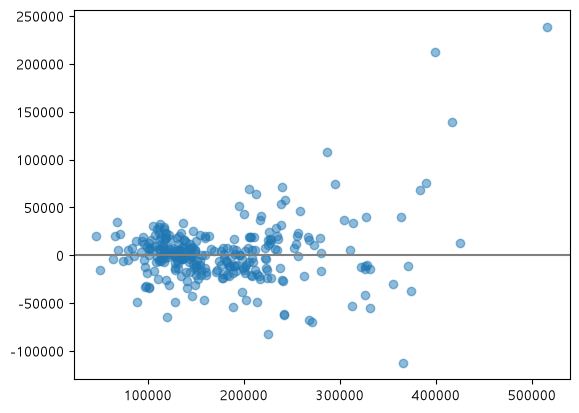

In [51]:
# 여기에 코드를 작성하세요
residual = y_test - best_pred
plt.scatter(best_pred, residual, alpha=0.5)
plt.axhline(0, color="gray")

> **[판단]** 잔차 그림에서 규칙이 보이나요? 예측 가격이 높은 쪽에서 점들이 어떻게 흩어져 있나요?
>
> 나의 답: 첫째, 예측 가격이 높아질수록 잔차가 넓게 퍼진다. 15만 달러 이하에서는 대부분 ±5만 달러 안에 모여 있지만, 20만~35만 달러에서는 ±10만 달러 가까이 퍼지고, 40만 달러 이상에서는 +24만 달러까지 벌어진다. 비싸게 예측한 집일수록 오차가 크다. 둘째, 30만 달러까지는 잔차가 0을 중심으로 위아래 고르게 분포하지만, 40만 달러 이상에서는 대부분 0보다 위에 있다. 잔차는 실제 − 예측이므로, 비싼 집은 실제보다 싸게 예측하는 경향이 있다는 뜻이다.

## 5-3. 가장 크게 틀린 집 들여다보기

**[직접 작성]** 최고 모델이 가장 크게 틀린 집 10채를 골라 실제 거래가, 예측 가격, 면적(`GrLivArea`), 품질(`OverallQual`), 동네(`Neighborhood`)를 한 표로 출력하세요.

<details><summary>힌트</summary>

`test_df.assign(예측=best_pred, 오차=y_test - best_pred)`로 열을 붙인 뒤, 오차의 절댓값으로 정렬합니다. `sort_values("오차", key=abs, ascending=False).head(10)`.
</details>

In [52]:
# 여기에 코드를 작성하세요
worst = (
    test_df
    .assign(예측=best_pred, 오차=y_test - best_pred)
    .sort_values("오차", key=abs, ascending=False)
    .head(10)
)

display(worst[["SalePrice", "예측", "오차", "GrLivArea", "OverallQual", "Neighborhood"]].round(0))

,SalePrice,예측,오차,GrLivArea,OverallQual,Neighborhood
691,755000,516019.0,238981.0,4316,10,NoRidge
898,611657,398955.0,212702.0,2364,9,NridgHt
1046,556581,417006.0,139575.0,2868,9,StoneBr
581,253293,365415.0,-112122.0,2042,8,NridgHt
774,395000,286980.0,108020.0,1973,8,NridgHt
588,143000,225154.0,-82154.0,1473,5,ClearCr
1243,465000,389555.0,75445.0,2076,10,NridgHt
585,369900,295269.0,74631.0,2028,8,Timber
218,311500,240172.0,71328.0,1954,7,Crawfor
1173,200500,270721.0,-70221.0,3086,5,ClearCr


> **[판단]** 크게 틀린 집들에게 공통점이 있나요? 기획팀이 "이런 매물에는 자동 시세를 쓰지 말자"고 한다면 어떤 기준(가격대, 품질 등)을 제안하겠습니까?
>
> 나의 답: 공통점이 있다. 10채 중 7채가 품질(OverallQual) 8등급 이상이고, 특히 가장 크게 틀린 3채는 모두 품질 9~10등급의 55만 달러 이상 집으로, 14만~24만 달러나 싸게 예측됐다. 고급 주택은 학습 데이터에 적어 모델이 잘 배우지 못했기 때문으로 보인다. 그래서 "품질 9등급 이상인 매물은 자동 시세 대신 사람이 검토한다"는 기준을 제안하겠다.

## 5-4. 가격 맞히기

곧 다른 수강생들의 결과와 함께 비교합니다. 그 전에 **사람의 감**으로 세 채의 가격을 먼저 맞혀 봅니다.

**[제공]** 평가용 집 세 채의 정보를 보여 줍니다. (거래가는 보여 주지 않습니다.)

In [53]:
# [제공] 맞혀 볼 집 세 채 (거래가는 숨김)
_s = test_df.sort_values("SalePrice")
guess_ids = [_s.index[int(q * (len(_s) - 1))] for q in (0.05, 0.5, 0.99)]
show_cols = ["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars", "KitchenQual"]
test_df.loc[guess_ids, show_cols]

,Neighborhood,GrLivArea,OverallQual,YearBuilt,TotalBsmtSF,GarageCars,KitchenQual
649,MeadowV,630,4,1970,630,0,TA
1299,NAmes,1246,5,1959,1246,1,Gd
1243,NridgHt,2076,10,2006,2076,3,Ex


**[직접 작성]** 위 표만 보고, 세 집의 거래가를 직관으로 적으세요. (`my_guess`의 0을 달러 숫자로 바꿉니다.)

In [54]:
# 위 표의 순서대로 세 집의 거래가(달러)를 적으세요
my_guess = {guess_ids[0]: 150000, guess_ids[1]: 200000, guess_ids[2]: 700000}

**[제공]** 실제 거래가를 공개합니다. 내 감, 내 시세 규칙, 최고 모델의 예측을 나란히 봅니다.

In [57]:
# [제공] 정답 공개
reveal = pd.DataFrame({
    "실제 거래가": y_test.loc[guess_ids],
    "내 감": pd.Series(my_guess),
    "내 시세 규칙": preds["시세 규칙(품질별 단가 × 면적)"].loc[guess_ids],
    "최고 모델": best_pred.loc[guess_ids],
})
for col in ["내 감", "내 시세 규칙", "최고 모델"]:
    reveal[col + " 오차"] = (reveal[col] - reveal["실제 거래가"]).abs()
reveal.round(0)

,실제 거래가,내 감,내 시세 규칙,최고 모델,내 감 오차,내 시세 규칙 오차,최고 모델 오차
649,84500,150000,62612.0,79394.0,65500,21888.0,5106.0
1299,154000,200000,145079.0,140022.0,46000,8921.0,13978.0
1243,465000,700000,345536.0,389555.0,235000,119464.0,75445.0


> **[판단]** 세 방법(내 감, 내 시세 규칙, 모델) 중 가장 가까웠던 것은 무엇인가요? 가장 비싼 집에서는 어땠나요? 5-1의 결과와 연결해서 설명해 보세요.
>
> 나의 답: 세 집 중 두 집(649번, 1243번)은 최고 모델이 가장 가까웠고, 중간 가격의 1299번은 내 시세 규칙이 가장 가까웠다(오차 8,921, 모델은 13,978). 내 감은 세 집 모두 실제보다 비싸게 짐작해 매번 가장 크게 틀렸다. 가장 비싼 1243번(465,000달러)에서는 시세 규칙(345,536)과 모델(389,555) 모두 실제보다 낮게 예측했지만, 모델이 더 가까웠다. 이는 5-1에서 300,000~500,000달러 구간의 평균 편향이 두 방법 모두 양수였고, 그 구간의 MAE는 모델이 더 낮았던 결과와 일치한다.

## 5-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

시세 규칙은 나의 시세 규칙 하나만 있는 것이 아닙니다. 다른 정보를 골랐다면 결과도 달랐을 것입니다. 다음 절에서는 아래 **후보 정보 5개** 중 1개 또는 2개를 고르고, **계산법 2가지** 중 하나를 쓰는 시세 규칙을 **모두** 만들어 채점합니다. 정보 조합 5 + 10 = 15가지 × 계산법 2가지 = **30개**입니다.

| 후보 정보 | 나누는 방법 |
| --- | --- |
| 동네 (`Neighborhood`) | 동네 이름 그대로 |
| 품질 등급 (`OverallQual`) | 1~10 등급 그대로 |
| 거주 면적 (`GrLivArea`) | 학습용 기준 5구간 (집 수가 같도록) |
| 건축 연도 (`YearBuilt`) | 학습용 기준 5구간 (집 수가 같도록) |
| 차고 차량 수 (`GarageCars`) | 0~4대 그대로 |

| 계산법 | 뜻 |
| --- | --- |
| (가) 그룹 중앙값 | 같은 그룹 집들의 거래가 중앙값을 그대로 시세로 쓴다 |
| (나) 그룹 단가 × 면적 | 같은 그룹 집들의 평방피트당 단가 중앙값에 그 집의 거주 면적을 곱한다 |

예: "동네 + 품질 등급, (가)"는 "같은 동네·같은 품질 등급 집들의 거래가 중앙값"을 시세로 쓰는 규칙입니다. 모든 그룹의 숫자는 학습용 데이터에서만 계산합니다.

> **[판단]** 예상 ① 기록표에서 가장 좋은 모델(평가 MAE 약 20,000달러)은 시세 규칙 30개 중 몇 개보다 MAE가 낮을까요?
>
> 나의 답: 20개. 내 시세 규칙(MAE 32,665)도 모델보다 1만 2천 달러 이상 뒤졌으므로 대부분의 규칙은 모델보다 못하겠지만, 잘 고른 정보 조합 몇 개는 모델에 가까울 수 있다고 생각한다.

> **[판단]** 예상 ② 30개 중 MAE가 가장 낮은 시세 규칙은 어떤 정보를 쓰고, 어떤 계산법일까요? 이유도 적어 보세요.
>
> 나의 답: 품질 등급과 거주 면적을 쓰고, 계산법은 (나) 그룹 단가 × 면적일 것이다. 1-6에서 거래가와 상관이 가장 높은 두 정보가 품질과 면적이었고, (나)는 그룹 안의 집 크기 차이까지 반영할 수 있기 때문이다.

## 5-6. 시세 규칙 30개 채점하기

**[직접 작성]** `my_rule_text`에 나의 시세 규칙을 한 줄로 적으세요. 아래 결과에서 나의 시세 규칙을 표시할 때 씁니다. (예: `"동네별 평방피트당 단가 × 거주 면적"`)

In [58]:
my_rule_text = "품질 등급별 평방피트당 단가 X 거주 면적"

**[제공]** 후보 정보 5개 중 1~2개 × 계산법 2가지로 시세 규칙 30개를 만들고, 평가용 데이터에서 채점합니다.

In [ ]:
# [제공] 시세 규칙 30개 만들기
from itertools import combinations

def train_bins(col, q=5):
    """학습용 데이터로 집 수가 같은 q개 구간의 경계를 정하고, 그 경계로 학습용·평가용을 나눕니다."""
    edges = np.unique(np.quantile(train_df[col], np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(train_df[col], edges).astype(str), pd.cut(test_df[col], edges).astype(str)

groupers = {
    "동네": (train_df["Neighborhood"].astype(str), test_df["Neighborhood"].astype(str)),
    "품질 등급": (train_df["OverallQual"].astype(str), test_df["OverallQual"].astype(str)),
    "면적 구간": train_bins("GrLivArea"),
    "연도 구간": train_bins("YearBuilt"),
    "차고": (train_df["GarageCars"].astype(str), test_df["GarageCars"].astype(str)),
}
price_tr = train_df["SalePrice"]
unit_tr = train_df["SalePrice"] / train_df["GrLivArea"]

rows = []
for n in [1, 2]:
    for combo in combinations(groupers, n):
        key_tr = groupers[combo[0]][0].copy()
        key_te = groupers[combo[0]][1].copy()
        for c in combo[1:]:
            key_tr = key_tr + " | " + groupers[c][0]
            key_te = key_te + " | " + groupers[c][1]
        # (가) 그룹 중앙값
        med = price_tr.groupby(key_tr).median()
        pred_a = key_te.map(med).fillna(price_tr.median())
        # (나) 그룹 단가 × 면적
        unit = unit_tr.groupby(key_tr).median()
        pred_b = key_te.map(unit).fillna(unit_tr.median()) * test_df["GrLivArea"]
        for method, pred in [("(가) 그룹 중앙값", pred_a), ("(나) 그룹 단가 × 면적", pred_b)]:
            err = (test_df["SalePrice"] - pred).abs()
            rows.append({"정보": " + ".join(combo), "정보 수": n, "계산법": method, "평가 MAE": float(err.mean())})

rules = pd.DataFrame(rows).sort_values("평가 MAE", ignore_index=True)
print("만든 시세 규칙 수:", len(rules))
rules.head(10).round(0)

만든 시세 규칙 수: 30


,정보,정보 수,계산법,평가 MAE
0,품질 등급 + 면적 구간,2,(나) 그룹 단가 × 면적,25031.0
1,품질 등급 + 면적 구간,2,(가) 그룹 중앙값,26569.0
2,동네 + 면적 구간,2,(나) 그룹 단가 × 면적,26712.0
3,동네 + 면적 구간,2,(가) 그룹 중앙값,26821.0
4,동네 + 품질 등급,2,(가) 그룹 중앙값,27599.0
5,품질 등급 + 차고,2,(가) 그룹 중앙값,28281.0
6,품질 등급 + 연도 구간,2,(가) 그룹 중앙값,29385.0
7,면적 구간 + 차고,2,(나) 그룹 단가 × 면적,29402.0
8,동네 + 품질 등급,2,(나) 그룹 단가 × 면적,29580.0
9,면적 구간 + 연도 구간,2,(나) 그룹 단가 × 면적,29676.0


**[제공]** 가장 좋은 모델과 나의 시세 규칙이 30개 규칙 사이에서 어디쯤인지 봅니다.

가장 좋은 모델 [숫자+범주] 평가 MAE 20,172
  MAE로 이기는 시세 규칙: 30개 / 30개
나의 시세 규칙 [품질 등급별 평방피트당 단가 X 거주 면적] 평가 MAE 32,665
  30개 중 나보다 MAE가 낮은 시세 규칙: 20개

정보 수 × 계산법별 MAE 중앙값
계산법   (가) 그룹 중앙값  (나) 그룹 단가 × 면적
정보 수                            
1        39265.0         32983.0
2        30329.0         29749.0


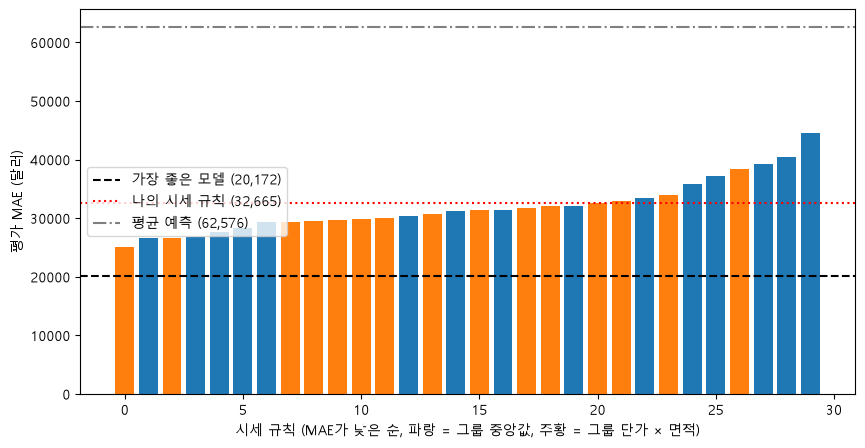

In [ ]:
# [제공] 모델과 나의 시세 규칙의 위치
_log = pd.DataFrame(experiment_log)
_models = _log[_log["학습 MAE"].notna()]
_best = _models.sort_values("평가 MAE", kind="stable").iloc[0]
best_mae = float(_best["평가 MAE"])
my_mae = float(m_rule["MAE"])

print(f"가장 좋은 모델 [{_best['실험']}] 평가 MAE {best_mae:,.0f}")
print(f"  MAE로 이기는 시세 규칙: {(rules['평가 MAE'] > best_mae).sum()}개 / {len(rules)}개")
print(f"나의 시세 규칙 [{my_rule_text}] 평가 MAE {my_mae:,.0f}")
print(f"  30개 중 나보다 MAE가 낮은 시세 규칙: {(rules['평가 MAE'] < my_mae).sum()}개")
print()
print("정보 수 × 계산법별 MAE 중앙값")
print(rules.pivot_table(index="정보 수", columns="계산법", values="평가 MAE", aggfunc="median").round(0))

fig, ax = plt.subplots(figsize=(10, 5))
colors = rules["계산법"].map({"(가) 그룹 중앙값": "tab:blue", "(나) 그룹 단가 × 면적": "tab:orange"})
ax.bar(range(len(rules)), rules["평가 MAE"], color=colors)
ax.axhline(best_mae, color="black", linestyle="--", label=f"가장 좋은 모델 ({best_mae:,.0f})")
ax.axhline(my_mae, color="red", linestyle=":", label=f"나의 시세 규칙 ({my_mae:,.0f})")
ax.axhline(m_mean["MAE"], color="gray", linestyle="-.", label=f"평균 예측 ({m_mean['MAE']:,.0f})")
ax.set_xlabel("시세 규칙 (MAE가 낮은 순, 파랑 = 그룹 중앙값, 주황 = 그룹 단가 × 면적)")
ax.set_ylabel("평가 MAE (달러)")
ax.legend(loc="center left")
plt.show()

## 5-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: 예상 ①은 틀렸고 ②는 맞았다. 가장 크게 빗나간 것은 ①이다. 20개라고 예상했지만 실제로는 모델이 30개 전부를 이겼고, 가장 좋은 시세 규칙(품질 등급 + 면적 구간, (나), MAE 25,031)도 모델(20,172)보다 약 4,900달러 뒤졌다. 잘 고른 정보 조합이라면 모델에 가까울 것이라고 생각했지만, 시세 규칙은 정보를 두 개까지만 쓰고 같은 그룹 안의 집에는 하나의 값만 쓴다. 반면 모델은 18개 정보를 한꺼번에 쓰고 집마다 다른 값을 계산한다. 예상 ②는 거래가와 상관이 가장 높은 품질과 면적을 쓰고, 면적을 곱해 크기 차이를 반영할 것이라는 근거대로 "품질 등급 + 면적 구간, (나)"가 1위였다.

> **[판단]** 정보를 1개 쓴 규칙과 2개 쓴 규칙, 계산법 (가)와 (나) 중 어느 쪽의 MAE가 대체로 낮은가요? 계산법 (나)가 유리하거나 불리한 경우는 어떤 정보를 쓸 때인지도 표에서 찾아 보세요.
>
> 나의 답: 정보를 1개 쓴 규칙보다 2개 쓴 규칙이 더 낮고 가와 나 중에서도 나가 대체로 낮다. MAE 중앙값으로 보면 정보 1개일 때는 나가 가보다 6,282 낮지만, 2개일 때는 580만 낮아 차이가 작다. (나)는 면적 구간으로 그룹을 나눈 규칙에서 유리했고 면적 구간을 쓰지 않은 규칙에서는 불리했다. (나)는 가격이 면적에 정비례한다고 가정하는데, 실제로는 큰 집일수록 평방피트당 단가가 낮다. 면적 구간으로 묶으면 비슷한 크기의 집끼리 단가를 구하므로 이 가정이 잘 맞지만, 크기가 섞인 그룹의 단가를 아주 크거나 작은 집에 곱하면 크게 빗나가기 때문이다.

> **[판단]** 가장 좋은 시세 규칙과 가장 좋은 모델의 MAE 차이는 얼마인가요? 이 차이와, 시세 규칙은 누구나 이해하고 바로 쓸 수 있다는 점을 함께 놓고 보면 기획팀에 무엇을 권하겠습니까?
>
> 나의 답: 차이는 약 4,900달러이다. 오차가 꽤 크다는 것을 알 수 있다. 또한 가장 좋은 모델은 선형 회귀라 근거를 설명할 수 있고 운영 부담도 크지 않으므로 모델 도입을 권하겠다.

> **[판단]** 나의 시세 규칙은 30개 사이에서 어디쯤인가요? 정보를 하나 더하거나 계산법을 바꾼다면 어떤 규칙을 고르겠습니까? 위 표에서 그 규칙을 찾아 결과를 적어 보세요.
>
> 나의 답: 나의 시세 규칙(품질 등급, (나), MAE 32,665)보다 MAE가 낮은 규칙이 20개라 30개 중 21위로, 중간보다 아래다. 정보를 하나 더한다면 면적 구간을 더해 "품질 등급 + 면적 구간, (나)"를 고르겠다. 이 규칙은 MAE 25,031로 30개 중 1위이며, 내 규칙보다 7,634(약 23%) 낮다. 계산법은 바꾸지 않겠다. 정보가 1개일 때 MAE 중앙값이 (가) 39,265, (나) 32,983으로 (가)가 크게 불리했기 때문이다.

## 5-6. 기획팀 보고 메모

분석 결과를 기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **오차를 어떤 지표로 말할 것인가**: MAE와 RMSE 중 하나를 고르고, 의뢰서의 문장("너무 다르면 플랫폼을 믿지 않게 된다")에 근거해 이유를 쓴다. "평균적으로 ±얼마"를 달러로 적는다.
2. **지금 쓰는 방법(내 시세 규칙)과 비교해 얼마나 나은가**
3. **믿어도 되는 집과 믿으면 안 되는 집**: 5-1의 가격대별 오차에 근거해 구분 기준을 제안한다.
4. **주의할 점**: 1-4의 빈 값 처리 결정, 데이터의 한계(Ames 한 도시의 2006~2010년 거래), 아직 확인하지 못한 것

> **[판단]** 기획팀 보고 메모:
>
> 1. 오차 지표와 ±얼마:
>
> 2. 시세 규칙과의 비교:
>
> 3. 믿어도 되는 집 / 믿으면 안 되는 집:
>
> 4. 주의할 점:
>
> 나의 답: 
> 1. 오차 지표와 ±얼마: 의뢰서에 "너무 다르면 플랫폼을 믿지 않게 된다"고 했으므로, 크게 빗나간 경우를 더 무겁게 반영하는 지표(RMSE)로 오차를 말하겠습니다. 이 기준으로 새 방법의 시세는 실제 거래가와 평균적으로 약 ±33,000달러 차이 납니다.
>
> 2. 시세 규칙과의 비교: 지금 쓰는 방법(품질 등급별 평방피트당 단가 × 면적)은 같은 기준으로 약 ±44,000달러 차이가 납니다. 새 방법은 이보다 약 11,600달러(26%) 오차가 작습니다.
>
> 3. 믿어도 되는 집 / 믿으면 안 되는 집: 10만~20만 달러대 집은 평균 오차가 약 14,000달러로 믿을 만합니다. 반면 30만 달러가 넘는 집은 실제보다 낮게 매기는 경향이 있고, 50만 달러 이상은 평균 20만 달러 가까이 싸게 매겼습니다. 시세를 매기기 전에는 실제 가격을 모르므로, 크게 틀린 집에 공통으로 많았던 품질 9등급 이상 매물은 자동 시세 대신 사람이 검토할 것을 제안합니다.
>
> 4. 주의할 점: 수영장, 차고 등의 빈 칸은 "시설 없음"으로 처리했지만, 실제로는 기록이 빠진 경우가 섞여 있을 수 있습니다. 또 데이터가 Ames 한 도시의 2006~2010년 거래라서, 다른 도시나 최근 시세에 쓰면 오차가 더 커질 수 있습니다. 평가용 집을 한 번만 나눠 확인했고 50만 달러 이상 집은 3채뿐이어서, 다른 묶음에서도 같은 결과가 나오는지는 아직 확인하지 못했습니다.

---
# 마무리

## 이 Chapter의 판단 포인트

> **MAE와 RMSE 중 무엇을 보고서에 쓸 것인가? 큰 오차를 얼마나 아프게 볼지는 지표가 아니라 비즈니스가 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "회귀 모델의 오차를 보면 평균 예측과 현행 시세 규칙의 오차를 먼저 찾는다."

> **[판단]** 나의 체크리스트 2번(회귀 지표를 볼 때):
>
> 나의 답: 회귀 모델의 오차를 볼 때 MAE와 RMSE를 둘 다 확인한다. 두 지표가 반대로 움직이면 소수의 큰 오차가 있다는 신호이므로, 어느 지표를 기준으로 할지는 비즈니스 목적에 맞춰 정한다.

> **[판단]** 나의 체크리스트 3번(학습용 점수와 평가용 점수를 볼 때):
>
> 나의 답: 학습용과 평가용의 오차 차이를 확인한다. 3차 다항처럼 학습용 오차는 아주 작은데 평가용 오차가 크게 늘면 과적합으로 보고, 정규화(Ridge 등)나 더 단순한 모델을 시도한다.

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 3에서는 확률을 예측하는 **분류**를 배웁니다.